# Лабораторная работа 3
## Линейные структуры данных

## Выполнил Улискин Даниил Евгеньевич
## Группа ФИТ-241
## Вариант 5

In [2]:
%matplotlib inline
import operator
import random
import re
import time
import matplotlib.pyplot as plt

## № 1 (3 балла)

Возьмите реализацию класса `UnorderedList` из лекционных материалов и выполните следующие доработки:

1. Реализуйте методы `append(item)`, `index(item)`, `insert(pos, item)`, `pop()`, `pop(pos)`.
2. Реализуйте метод `__str__`, чтобы список отображался в Python-стиле.
3. Реализуйте метод среза, принимающий `start` и `stop` и возвращающий копию списка от `start` до `stop`, не включая `stop`.

Все доработки необходимо протестировать.

In [3]:
class Node:
    def __init__(self, data, next_node=None):
        self.data = data
        self.next = next_node


class UnorderedList:
    def __init__(self):
        self.head = None

    def __iter__(self):
        current = self.head
        while current is not None:
            yield current.data
            current = current.next

    def __str__(self):
        return '[' + ', '.join(repr(item) for item in self) + ']'

    def is_empty(self):
        return self.head is None

    def add(self, item):
        self.head = Node(item, self.head)

    def size(self):
        return sum(1 for _ in self)

    def search(self, item):
        return any(value == item for value in self)

    def remove(self, item):
        previous = None
        current = self.head
        while current is not None and current.data != item:
            previous, current = current, current.next
        if current is None:
            raise ValueError(f'{item!r} отсутствует в списке')
        if previous is None:
            self.head = current.next
        else:
            previous.next = current.next

    def append(self, item):
        new_node = Node(item)
        if self.head is None:
            self.head = new_node
            return
        current = self.head
        while current.next is not None:
            current = current.next
        current.next = new_node

    def index(self, item):
        for position, value in enumerate(self):
            if value == item:
                return position
        raise ValueError(f'{item!r} отсутствует в списке')

    def insert(self, pos, item):
        n = self.size()
        if pos < 0:
            pos = max(0, n + pos)
        pos = min(pos, n)
        if pos == 0:
            self.add(item)
            return
        previous = self.head
        for _ in range(pos - 1):
            previous = previous.next
        previous.next = Node(item, previous.next)

    def pop(self, pos=None):
        if self.head is None:
            raise IndexError('pop из пустого списка')
        if pos is None:
            if self.head.next is None:
                value = self.head.data
                self.head = None
                return value
            previous = self.head
            while previous.next.next is not None:
                previous = previous.next
            value = previous.next.data
            previous.next = None
            return value
        if pos < 0:
            pos += self.size()
        if pos == 0:
            value = self.head.data
            self.head = self.head.next
            return value
        if pos < 0:
            raise IndexError('индекс вне диапазона')
        previous = self.head
        for _ in range(pos - 1):
            if previous.next is None:
                raise IndexError('индекс вне диапазона')
            previous = previous.next
        if previous.next is None:
            raise IndexError('индекс вне диапазона')
        value = previous.next.data
        previous.next = previous.next.next
        return value

    def slice(self, start, stop):
        result = UnorderedList()
        start, stop, _ = slice(start, stop).indices(self.size())
        for position, value in enumerate(self):
            if start <= position < stop:
                result.append(value)
        return result


numbers = UnorderedList()
for value in [10, 20, 30]:
    numbers.append(value)
numbers.insert(1, 15)
assert str(numbers) == '[10, 15, 20, 30]'
assert numbers.index(20) == 2
assert numbers.pop() == 30
assert numbers.pop(1) == 15
assert str(numbers.slice(0, 2)) == '[10, 20]'
print('Все тесты пройдены:', numbers)

Все тесты пройдены: [10, 20]


## № 2 (2 балла)

Напишите функцию `move_to_front` для чтения `n` строк и сохранения их в связном списке без повторов. Новую строку нужно добавлять в начало. Если строка уже встречалась, её нужно удалить со старой позиции и снова поместить в начало.

In [ ]:
def move_to_front(n, input_func=input):
    result = UnorderedList()
    for i in range(n):
        value = input_func(f'Строка {i + 1}: ')
        if result.search(value):
            result.remove(value)
        result.add(value)
    return result


test_input = iter(['кот', 'пёс', 'лиса', 'кот', 'сова', 'лиса'])
result = move_to_front(6, lambda _: next(test_input))
assert str(result) == "['лиса', 'сова', 'кот', 'пёс']"
print(result)

# Для ручного ввода можно использовать: move_to_front(int(input('n = ')))

['лиса', 'сова', 'кот', 'пёс']
['лиса', 'сова', 'кот', 'пёс']


## № 3 (2 балла)

Напишите функцию, которая принимает первый узел односвязного списка, разворачивает список с разрушением исходного и возвращает новый первый узел. Реализуйте итеративный и рекурсивный варианты.

In [ ]:
def build_nodes(values):
    head = None
    for value in reversed(values):
        head = Node(value, head)
    return head


def nodes_to_list(head):
    result = []
    while head is not None:
        result.append(head.data)
        head = head.next
    return result


def reverse_iterative(head):
    previous = None
    current = head
    while current is not None:
        next_node = current.next
        current.next = previous
        previous = current
        current = next_node
    return previous


def reverse_recursive(head):
    if head is None or head.next is None:
        return head
    new_head = reverse_recursive(head.next)
    head.next.next = head
    head.next = None
    return new_head


assert nodes_to_list(reverse_iterative(build_nodes([1, 2, 3, 4]))) == [4, 3, 2, 1]
assert nodes_to_list(reverse_recursive(build_nodes([1, 2, 3, 4]))) == [4, 3, 2, 1]
print('Оба варианта правильно разворачивают список')

Оба варианта правильно разворачивают список


## № 4 (3 балла)

На основе `UnorderedList` реализуйте стек, очередь и дек. Проведите тестирование и эксперимент, сравнивающий производительность одной из структур с реализацией на основе списка Python.

In [ ]:
class Stack:
    def __init__(self):
        self.items = UnorderedList()

    def is_empty(self):
        return self.items.is_empty()

    def push(self, item):
        self.items.add(item)

    def pop(self):
        return self.items.pop(0)

    def peek(self):
        if self.is_empty():
            raise IndexError('стек пуст')
        return self.items.head.data

    def size(self):
        return self.items.size()


class Queue:
    def __init__(self):
        self.items = UnorderedList()

    def is_empty(self):
        return self.items.is_empty()

    def enqueue(self, item):
        self.items.add(item)

    def dequeue(self):
        return self.items.pop()

    def size(self):
        return self.items.size()


class Deque:
    def __init__(self):
        self.items = UnorderedList()

    def is_empty(self):
        return self.items.is_empty()

    def add_front(self, item):
        self.items.add(item)

    def add_rear(self, item):
        self.items.append(item)

    def remove_front(self):
        return self.items.pop(0)

    def remove_rear(self):
        return self.items.pop()

    def size(self):
        return self.items.size()


passed_checks = 0


def check(description, actual, expected):
    """Сравнивает фактический результат с ожидаемым и печатает итог."""
    global passed_checks
    status = actual == expected
    mark = 'OK' if status else 'ОШИБКА'
    print(
        f'{description:<51} получено: {actual!r:<8} '
        f'ожидалось: {expected!r:<8} {mark}'
    )
    assert status, (
        f'{description}: получено {actual!r}, ожидалось {expected!r}'
    )
    passed_checks += 1


def check_raises(description, operation, expected_error):
    """Проверяет, что недопустимая операция вызывает нужное исключение."""
    global passed_checks
    try:
        operation()
    except expected_error:
        print(
            f'{description:<51} получено: '
            f'{expected_error.__name__:<10} OK'
        )
        passed_checks += 1
    else:
        raise AssertionError(
            f'{description}: ожидалось {expected_error.__name__}'
        )


print('СТЕК — LIFO: последним добавлен, первым удалён')
stack = Stack()
check('Новый стек пуст', stack.is_empty(), True)
for value in (1, 2, 3):
    stack.push(value)
check('Размер после push(1), push(2), push(3)', stack.size(), 3)
check('Верхний элемент peek()', stack.peek(), 3)
check('Первый pop()', stack.pop(), 3)
check('Второй pop()', stack.pop(), 2)
check('Третий pop()', stack.pop(), 1)
check('Стек снова пуст', stack.is_empty(), True)
check_raises('pop() из пустого стека', stack.pop, IndexError)

print('\nОЧЕРЕДЬ — FIFO: первым добавлен, первым удалён')
queue = Queue()
check('Новая очередь пуста', queue.is_empty(), True)
for value in (1, 2, 3):
    queue.enqueue(value)
check(
    'Размер после enqueue(1), enqueue(2), enqueue(3)',
    queue.size(),
    3,
)
check('Первый dequeue()', queue.dequeue(), 1)
check('Второй dequeue()', queue.dequeue(), 2)
check('Третий dequeue()', queue.dequeue(), 3)
check('Очередь снова пуста', queue.is_empty(), True)
check_raises(
    'dequeue() из пустой очереди',
    queue.dequeue,
    IndexError,
)

print('\nДЕК — добавление и удаление с обоих концов')
deque_test = Deque()
check('Новый дек пуст', deque_test.is_empty(), True)
deque_test.add_front(2)
deque_test.add_front(1)
deque_test.add_rear(3)
check('Размер после добавления 1, 2, 3', deque_test.size(), 3)
check(
    'Удаление спереди remove_front()',
    deque_test.remove_front(),
    1,
)
check(
    'Удаление сзади remove_rear()',
    deque_test.remove_rear(),
    3,
)
check(
    'Удаление оставшегося элемента',
    deque_test.remove_front(),
    2,
)
check('Дек снова пуст', deque_test.is_empty(), True)
check_raises(
    'remove_rear() из пустого дека',
    deque_test.remove_rear,
    IndexError,
)

print(
    f'\nИТОГ: {passed_checks} из {passed_checks} '
    'проверок пройдены успешно.'
)

СТЕК — LIFO: последним добавлен, первым удалён
Новый стек пуст                                     получено: True     ожидалось: True     OK
Размер после push(1), push(2), push(3)              получено: 3        ожидалось: 3        OK
Верхний элемент peek()                              получено: 3        ожидалось: 3        OK
Первый pop()                                        получено: 3        ожидалось: 3        OK
Второй pop()                                        получено: 2        ожидалось: 2        OK
Третий pop()                                        получено: 1        ожидалось: 1        OK
Стек снова пуст                                     получено: True     ожидалось: True     OK
pop() из пустого стека                              получено: IndexError OK

ОЧЕРЕДЬ — FIFO: первым добавлен, первым удалён
Новая очередь пуста                                 получено: True     ожидалось: True     OK
Размер после enqueue(1), enqueue(2), enqueue(3)     получено: 3        ожидал

### Эксперимент

Сравним добавление и удаление всех элементов стека. В обеих реализациях одна операция имеет сложность `O(1)`, но встроенный список Python обычно быстрее благодаря оптимизации на уровне C.

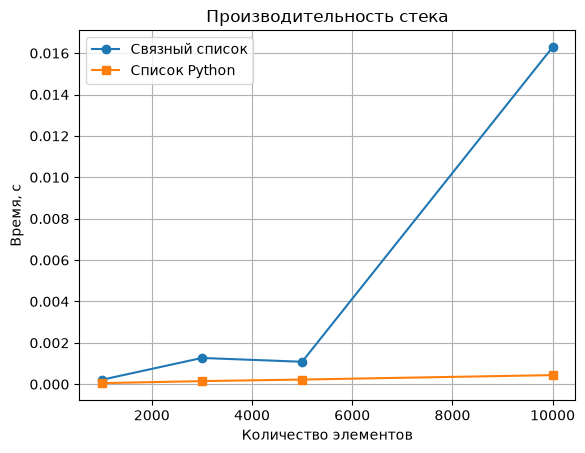

In [ ]:
def measure_stacks(n, repeats=3):
    linked_times = []
    python_times = []
    for _ in range(repeats):
        linked = Stack()
        start = time.perf_counter()
        for value in range(n):
            linked.push(value)
        for _ in range(n):
            linked.pop()
        linked_times.append(time.perf_counter() - start)

        python_stack = []
        start = time.perf_counter()
        for value in range(n):
            python_stack.append(value)
        for _ in range(n):
            python_stack.pop()
        python_times.append(time.perf_counter() - start)
    return sum(linked_times) / repeats, sum(python_times) / repeats


sizes = [1000, 3000, 5000, 10000]
linked_results, python_results = zip(*(measure_stacks(n) for n in sizes))
plt.plot(sizes, linked_results, 'o-', label='Связный список')
plt.plot(sizes, python_results, 's-', label='Список Python')
plt.xlabel('Количество элементов')
plt.ylabel('Время, с')
plt.title('Производительность стека')
plt.grid(True)
plt.legend()
plt.show()

## № 5 (2 балла)

Реализуйте класс `DoubleList` для двухсвязного списка. Каждый узел должен хранить ссылки на предыдущий и следующий узлы. Нужны методы проверки пустоты, поиска и размера, вставки и удаления в начале и конце, вставки до и после указанного узла и удаления указанного узла. Проведите тестирование.

In [ ]:
class DoubleNode:
    def __init__(self, data):
        self.data = data
        self.prev = None
        self.next = None


class DoubleList:
    def __init__(self):
        self.head = None
        self.tail = None
        self._size = 0

    def __iter__(self):
        current = self.head
        while current is not None:
            yield current.data
            current = current.next

    def __str__(self):
        return '[' + ', '.join(repr(item) for item in self) + ']'

    def is_empty(self):
        return self._size == 0

    def size(self):
        return self._size

    def search(self, item):
        current = self.head
        while current is not None:
            if current.data == item:
                return current
            current = current.next
        return None

    def add_first(self, item):
        node = DoubleNode(item)
        node.next = self.head
        if self.head is None:
            self.tail = node
        else:
            self.head.prev = node
        self.head = node
        self._size += 1
        return node

    def add_last(self, item):
        node = DoubleNode(item)
        node.prev = self.tail
        if self.tail is None:
            self.head = node
        else:
            self.tail.next = node
        self.tail = node
        self._size += 1
        return node

    def remove_first(self):
        if self.head is None:
            raise IndexError('список пуст')
        return self.remove_node(self.head)

    def remove_last(self):
        if self.tail is None:
            raise IndexError('список пуст')
        return self.remove_node(self.tail)

    def insert_before(self, node, item):
        if node is self.head:
            return self.add_first(item)
        new_node = DoubleNode(item)
        new_node.prev, new_node.next = node.prev, node
        node.prev.next = new_node
        node.prev = new_node
        self._size += 1
        return new_node

    def insert_after(self, node, item):
        if node is self.tail:
            return self.add_last(item)
        new_node = DoubleNode(item)
        new_node.prev, new_node.next = node, node.next
        node.next.prev = new_node
        node.next = new_node
        self._size += 1
        return new_node

    def remove_node(self, node):
        if node.prev is None:
            self.head = node.next
        else:
            node.prev.next = node.next
        if node.next is None:
            self.tail = node.prev
        else:
            node.next.prev = node.prev
        value = node.data
        node.prev = node.next = None
        self._size -= 1
        return value


double_list = DoubleList()
double_list.add_first(2)
double_list.add_first(1)
node_3 = double_list.add_last(3)
double_list.insert_before(node_3, 2.5)
double_list.insert_after(node_3, 4)
assert str(double_list) == '[1, 2, 2.5, 3, 4]'
assert double_list.remove_first() == 1
assert double_list.remove_last() == 4
double_list.remove_node(double_list.search(2.5))
assert str(double_list) == '[2, 3]' and double_list.size() == 2
print('Все тесты пройдены:', double_list)

Все тесты пройдены: [2, 3]


## № 6 (2 балла)

Напишите программу, которая с помощью стека проверяет соответствие открывающих и закрывающих тегов HTML-документа. За основу можно взять алгоритм проверки скобочной последовательности.

In [ ]:
VOID_TAGS = {'area', 'base', 'br', 'col', 'embed', 'hr', 'img', 'input', 'link', 'meta', 'source'}


def check_html(html):
    stack = Stack()
    tags = re.findall(r'<\s*(/?)\s*([A-Za-z][\w:-]*)\b([^>]*)>', html)
    for closing, name, attributes in tags:
        name = name.lower()
        if name in VOID_TAGS or attributes.strip().endswith('/'):
            continue
        if closing:
            if stack.is_empty() or stack.pop() != name:
                return False
        else:
            stack.push(name)
    return stack.is_empty()


valid_html = '''<html><head><title>Example</title></head>
<body><h1>Hello, world</h1><br></body></html>'''
invalid_html = '<html><body><h1>Ошибка</body></h1></html>'
assert check_html(valid_html) is True
assert check_html(invalid_html) is False
print('Корректный HTML:', check_html(valid_html))
print('Некорректный HTML:', check_html(invalid_html))

Корректный HTML: True
Некорректный HTML: False


## № 7 (2 балла)

Реализуйте стековый калькулятор. Программа должна читать выражение в обратной польской нотации и выводить результат либо сообщать, что выражение составлено некорректно.

In [ ]:
OPERATIONS = {
    '+': operator.add,
    '-': operator.sub,
    '*': operator.mul,
    '/': operator.truediv,
    '**': operator.pow,
}


def rpn_calculator(expression):
    stack = Stack()
    try:
        for token in expression.split():
            if token in OPERATIONS:
                if stack.size() < 2:
                    raise ValueError
                right = stack.pop()
                left = stack.pop()
                stack.push(OPERATIONS[token](left, right))
            else:
                stack.push(float(token))
        if stack.size() != 1:
            raise ValueError
        result = stack.pop()
        return int(result) if result.is_integer() else result
    except (ValueError, ZeroDivisionError, OverflowError):
        return 'Выражение составлено некорректно'


assert rpn_calculator('2 3 + 4 *') == 20
assert rpn_calculator('10 2 / 3 -') == 2
assert rpn_calculator('2 +') == 'Выражение составлено некорректно'
print(rpn_calculator('5 1 2 + 4 * + 3 -'))

14


## № 8 (4 балла). Вариант 5

Используя очередь, создайте симуляцию ситуации из реальной жизни: **студенты, сдающие экзамен преподавателю**. Укажите предположения и вероятностные данные сценария.

### Предположения

- Экзамен принимает один преподаватель, одновременно отвечает один студент.
- Всего приходит 30 студентов.
- Интервал между приходами имеет экспоненциальное распределение со средним 6 минут.
- Время ответа имеет треугольное распределение: минимум 8, максимум 25, наиболее вероятно 15 минут.
- Вероятность успешной сдачи каждого студента равна 80%.
- Студенты обслуживаются в порядке прихода и не покидают очередь.

Количество студентов: 30
Среднее ожидание: 135.7 мин.
Максимальное ожидание: 265 мин.
Максимальная длина очереди: 17
Сдали экзамен: 26 из 30


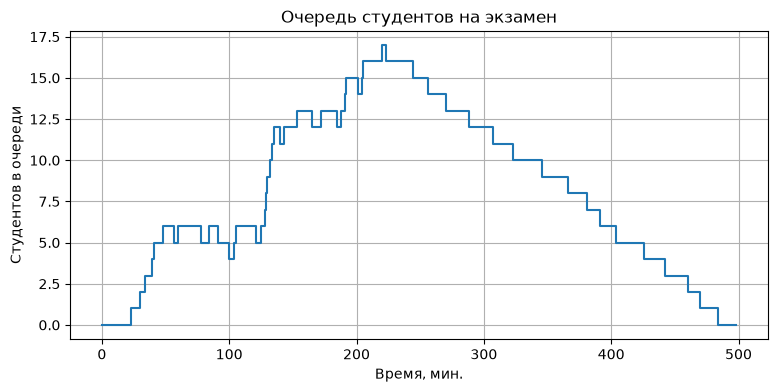

In [ ]:
def simulate_exam(student_count=30, seed=5):
    rng = random.Random(seed)
    students = []
    arrival = 0
    for number in range(1, student_count + 1):
        arrival += max(1, round(rng.expovariate(1 / 6)))
        students.append({
            'number': number,
            'arrival': arrival,
            'duration': round(rng.triangular(8, 25, 15)),
            'passed': rng.random() < 0.8,
        })

    waiting = Queue()
    next_student = 0
    current = None
    exam_end = None
    minute = 0
    results = []
    queue_history = []

    while next_student < len(students) or not waiting.is_empty() or current is not None:
        while next_student < len(students) and students[next_student]['arrival'] <= minute:
            waiting.enqueue(students[next_student])
            next_student += 1

        if current is not None and minute >= exam_end:
            current['finish'] = minute
            current['wait'] = current['start'] - current['arrival']
            results.append(current)
            current = None

        if current is None and not waiting.is_empty():
            current = waiting.dequeue()
            current['start'] = minute
            exam_end = minute + current['duration']

        queue_history.append(waiting.size())
        minute += 1

    return results, queue_history


exam_results, queue_history = simulate_exam()
waits = [student['wait'] for student in exam_results]
passed = sum(student['passed'] for student in exam_results)
print('Количество студентов:', len(exam_results))
print(f'Среднее ожидание: {sum(waits) / len(waits):.1f} мин.')
print('Максимальное ожидание:', max(waits), 'мин.')
print('Максимальная длина очереди:', max(queue_history))
print(f'Сдали экзамен: {passed} из {len(exam_results)}')

plt.figure(figsize=(9, 4))
plt.step(range(len(queue_history)), queue_history, where='post')
plt.xlabel('Время, мин.')
plt.ylabel('Студентов в очереди')
plt.title('Очередь студентов на экзамен')
plt.grid(True)
plt.show()

### Вывод

Очередь работает по принципу FIFO: первым отвечает студент, который раньше пришёл. Если среднее время ответа больше среднего интервала между приходами, очередь постепенно растёт. Фиксированный `seed` делает эксперимент воспроизводимым.